# Websky radio spectral indices

The points sit at the geometric mean of each band pair. Whiskers show the population width in Websky.

[Websky, arXiv v2, Fig. 4](https://arxiv.org/pdf/2110.15357v2#page=5) · [Massardi et al., Table 5](https://academic.oup.com/mnras/article/436/4/2915/984401) · [PS4C estimator](https://gitlab.com/giuse.puglisi/PS4C/-/blob/49cacf22374457a692c4ff896948f3ffc541815d/ps4c/sed_modelling.py#L45-90)

In [1]:
import csv
from io import StringIO
from urllib.request import urlopen

import matplotlib.pyplot as plt
import numpy as np

# Band edges (GHz), center, and width from the red curves in arXiv v2, Fig. 4.
knots = np.array([
    [4.8, 8.6, -0.600, 0.500],
    [4.8,  18, -1.270, 0.600],
    [8.6,  18, -0.950, 0.600],
    [ 30,  44, -0.173, 0.563],
    [ 44,  70, -0.505, 0.746],
    [ 70, 100, -0.548, 0.622],
    [100, 143, -0.665, 0.438],
    [143, 217, -0.428, 0.360],
    [217, 353, -0.544, 0.550],
])
low, high, center, width = knots.T
nu = np.sqrt(low * high)
massardi_steep = [-0.60, -0.95, -1.27]  # Table 5 in the band order above.

In [2]:
release = "https://gitlab.com/giuse.puglisi/PS4C/-/raw/49cacf22374457a692c4ff896948f3ffc541815d/data"
planck_center, planck_width, cut_center = [], [], []
for lo, hi in knots[3:8, :2].astype(int):
    with urlopen(f"{release}/Spectral_indices_matches_{lo}_{hi}.dat", timeout=30) as response:
        rows = list(csv.DictReader(StringIO(response.read().decode()), delimiter=" "))
    alpha = np.array([float(row["ALPHA"]) for row in rows])
    b = np.array([float(row["GLAT"]) for row in rows])
    p16, median, p84 = np.quantile(alpha, [0.16, 0.5, 0.84])
    planck_center.append(median)
    planck_width.append((p84 - p16) / 2)
    cut_center.append(np.median(alpha[np.abs(b) >= 20]))

# The five measured Planck pairs reproduce the figure to its tabulated precision here.
np.testing.assert_allclose(planck_center, center[3:8], atol=0.0005)
np.testing.assert_allclose(planck_width, width[3:8], atol=0.0005)

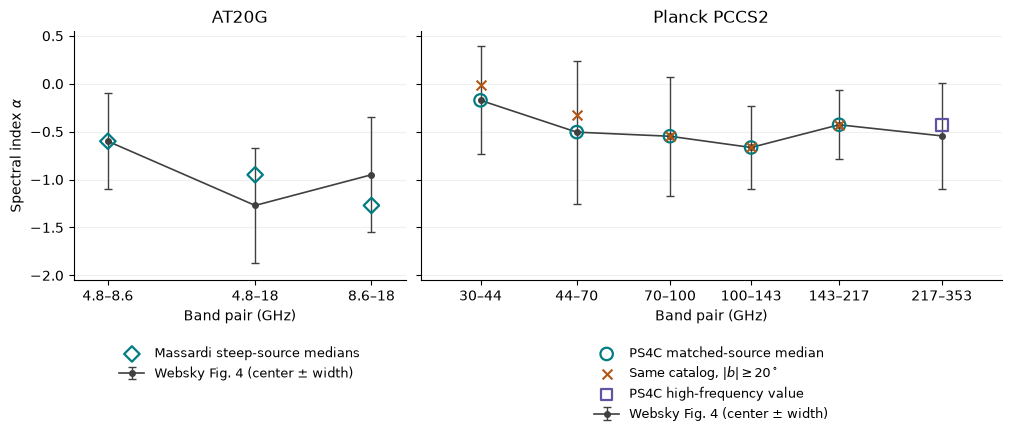

In [3]:
fig, (at20g, planck) = plt.subplots(
    1, 2, figsize=(10, 4.2), sharey=True, width_ratios=[1, 1.75], layout="constrained"
)
for ax, indices in [(at20g, slice(0, 3)), (planck, slice(3, 9))]:
    ax.set_xscale("log")
    ax.errorbar(nu[indices], center[indices], yerr=width[indices], fmt="o-", color="0.25",
                ms=4, lw=1.2, elinewidth=1, capsize=3, label="Websky Fig. 4 (center ± width)")
    ax.set_xticks(nu[indices], [f"{l:g}–{h:g}" for l, h in zip(low[indices], high[indices])])
    ax.minorticks_off()
    ax.set_xlabel("Band pair (GHz)")
    ax.grid(axis="y", alpha=0.18)
    ax.spines[["right", "top"]].set_visible(False)
    ax.margins(x=0.13)

at20g.set(title="AT20G", ylabel=r"Spectral index $\alpha$", ylim=(-2.05, 0.55))
at20g.scatter(nu[:3], massardi_steep, s=62, marker="D", facecolors="none",
              edgecolors="#007c83", linewidths=1.6, zorder=3, label="Massardi steep-source medians")
planck.set_title("Planck PCCS2")
planck.scatter(nu[3:8], planck_center, marker="o", s=80, facecolors="none",
               edgecolors="#007c83", linewidths=1.6, zorder=3, label="PS4C matched-source median")
planck.scatter(nu[3:8], cut_center, marker="x", s=50, color="#b35612", zorder=4,
               label=r"Same catalog, $|b|\geq20^\circ$")
# For radio sources above 217 GHz, this PS4C release reuses the 143–217 distribution.
planck.scatter(nu[-1], planck_center[-1], marker="s", s=70, facecolors="none",
               edgecolors="#6353a4", linewidths=1.6, zorder=3, label="PS4C high-frequency value")
for ax in (at20g, planck):
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), frameon=False, fontsize=9)
plt.show()